# Support Vector Machine: Reading Handwritten Digits

**Family:** Supervised learning | **Level:** Intermediate | **Dataset:** `digits` | **Runs on:** CPU, about 2 minute(s)

Find the maximum margin boundary and bend it with the RBF kernel.

## Table of Contents

1. [Learning Objectives](#1.-Learning-Objectives)
2. [Real-World Problem](#2.-Real-World-Problem)
3. [Research Paper](#3.-Research-Paper)
4. [Mathematical Foundation](#4.-Mathematical-Foundation)
5. [Dataset Introduction](#5.-Dataset-Introduction)
6. [Exploratory Data Analysis](#6.-Exploratory-Data-Analysis)
7. [Data Preprocessing](#7.-Data-Preprocessing)
8. [Algorithm Implementation](#8.-Algorithm-Implementation)
9. [Model Training](#9.-Model-Training)
10. [Evaluation](#10.-Evaluation)
11. [Visualization](#11.-Visualization)
12. [Interpretation](#12.-Interpretation)
13. [Experiments and Challenges](#13.-Experiments-and-Challenges)
14. [Research Discussion](#14.-Research-Discussion)
15. [Summary and Further Reading](#15.-Summary-and-Further-Reading)

## 1. Learning Objectives

**After this notebook you will understand:**

- What the margin is and why maximising it helps
- How the kernel trick gives nonlinear boundaries
- How C and gamma control flexibility
- How support vectors define the model

**Prerequisites:**

- Logistic regression notebook
- Vectors and dot products

**Skills you will have afterwards:**

- Choose a hyperparameter on validation data
- Compare with a baseline
- Run a sensitivity experiment

## 2. Real-World Problem

**Context.** Postal services, banks and forms processing read handwritten digits automatically.

**The problem.** Classify 8 by 8 pixel images of handwritten digits into ten classes.

**Why it matters.** Every misread digit is a mis-sorted letter or a wrong amount.

**Why machine learning.** Writing styles vary too much for hand made rules.

**Why this algorithm.** SVMs were among the strongest digit classifiers in the 1990s and remain strong on small image sets.

## 3. Research Paper

Entries are grouped by type. Bibliographic details marked *verified* were checked against the publisher record (Crossref) or the arXiv abstract page on 2026-11-17. Entries marked *not verified* come from the author's knowledge and must be checked before citing.

### Support-vector networks

- **Type:** foundational paper
- **Authors:** Cortes, C. and Vapnik, V.
- **Year and venue:** 1995, Machine Learning 20(3):273-297
- **DOI or URL:** https://doi.org/10.1007/BF00994018
- **Verification:** Crossref 2026-11-17
- **Research objective:** Introduce the soft margin support vector machine for non separable data.
- **Methodology:** Maximise the margin in a kernel feature space with slack variables.
- **Dataset:** Handwritten digit recognition (USPS and NIST data) and synthetic examples.
- **Main findings:** Polynomial kernel machines matched the best published digit classifiers of the time.
- **Limitations:** Training cost grows quickly with the number of rows. Needs feature scaling and kernel tuning.

### The Elements of Statistical Learning (2nd ed.)

- **Type:** foundational paper
- **Authors:** Hastie, T., Tibshirani, R. and Friedman, J.
- **Year and venue:** 2009, Springer
- **DOI or URL:** https://doi.org/10.1007/978-0-387-84858-7
- **Verification:** not verified in build environment
- **Research objective:** Textbook on statistical learning.
- **Methodology:** Textbook.
- **Dataset:** Not applicable.
- **Main findings:** Reference text.
- **Limitations:** Textbook.

**Relationship to this notebook.** Cortes and Vapnik demonstrated support vector networks on handwritten digits (USPS and NIST data). We use the UCI optical digits, which are smaller and different, so no number is comparable. This notebook does not reproduce the experimental protocol of any listed paper. It uses a different dataset and split, so numbers are not comparable with the paper.

## 4. Mathematical Foundation

**Hard margin.** Find $w, b$ maximising the margin $2/\lVert w\rVert$ subject to $y_i(w^\top x_i + b) \ge 1$.

**Soft margin primal.**

$$\min_{w,b,\xi}\; \tfrac12\lVert w\rVert^2 + C\sum_i \xi_i \quad \text{s.t.}\quad y_i(w^\top\phi(x_i)+b)\ge 1-\xi_i,\; \xi_i \ge 0$$

**Dual and kernel.** $f(x) = \sum_i \alpha_i y_i K(x_i, x) + b$, with RBF kernel $K(x,x') = \exp(-\gamma\lVert x-x'\rVert^2)$. Only points with $\alpha_i > 0$ (support vectors) matter.

**Multiclass.** scikit-learn trains one versus one classifiers and votes.

**Limitations.** Training cost grows quickly with rows, needs scaling, and raw scores are not probabilities (Platt scaling is used when `probability=True`).

## 5. Dataset Introduction

**Optical Recognition of Handwritten Digits**, UCI, licence CC BY 4.0, DOI 10.24432/C50P49. scikit-learn ships 1797 images (the test part of the UCI data) as 8 by 8 grids, so 64 integer pixel features from 0 to 16. Target `digit`, ten classes. Limit: far smaller than MNIST.

The table printed below the next cell comes from the dataset registry in `src/ml_lab/data/registry.py`. Licence terms belong to the data provider, not to this repository.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.base import clone
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.inspection import permutation_importance
from sklearn.model_selection import cross_validate
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from ml_lab.data import load_dataset, missing_report
from ml_lab.preprocessing import split_three_way, build_preprocessor, make_model_pipeline, feature_names
from ml_lab.evaluation import evaluate_estimator, compare_models
from ml_lab.experiments import ExperimentRecord, save_figure
from ml_lab.utils import set_seed, print_environment
from ml_lab import visualization as viz

NOTEBOOK_ID = "support_vector_machine"
SEED = 42
set_seed(SEED)
viz.apply_style()
print_environment()

python 3.13.18 | Linux-6.18.44-fc-v595-x86_64-with-glibc2.39
  numpy==2.5.3
  pandas==3.0.5
  scipy==1.18.1
  scikit-learn==1.9.1
  matplotlib==3.11.2
  xgboost==3.4.1
  lightgbm==4.7.0
  catboost==1.2.10
  umap-learn==0.6.0
  torch==2.15.0
  gymnasium==1.4.0


In [2]:
bundle = load_dataset("digits")
data = bundle.frame
TASK = bundle.task
TARGET = bundle.target
print("task:", TASK, "| target:", TARGET, "| shape:", data.shape)
display(pd.Series(bundle.describe_source(), name="source").to_frame())
display(data.head())

task: classification | target: digit | shape: (1797, 65)


,source
title,Optical Recognition of Handwritten Digits
source,UCI Machine Learning Repository
url,https://archive.ics.uci.edu/dataset/80/optical...
license,CC BY 4.0
doi,10.24432/C50P49
rows,1797
features,64
limits,"8x8 images, much smaller than MNIST."


,pixel_0_0,pixel_0_1,pixel_0_2,pixel_0_3,pixel_0_4,pixel_0_5,pixel_0_6,pixel_0_7,pixel_1_0,pixel_1_1,...,pixel_6_7,pixel_7_0,pixel_7_1,pixel_7_2,pixel_7_3,pixel_7_4,pixel_7_5,pixel_7_6,pixel_7_7,digit
0,0.0,0.0,5.0,13.0,9.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,6.0,13.0,10.0,0.0,0.0,0.0,0
1,0.0,0.0,0.0,12.0,13.0,5.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,11.0,16.0,10.0,0.0,0.0,1
2,0.0,0.0,0.0,4.0,15.0,12.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,3.0,11.0,16.0,9.0,0.0,2
3,0.0,0.0,7.0,15.0,13.0,1.0,0.0,0.0,0.0,8.0,...,0.0,0.0,0.0,7.0,13.0,13.0,9.0,0.0,0.0,3
4,0.0,0.0,0.0,1.0,11.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,2.0,16.0,4.0,0.0,0.0,4


## 6. Exploratory Data Analysis

We look at size, types, missing values, the target, feature distributions, correlation and outliers before any modelling. Pixel values run from 0 to 16 and some border pixels are always zero.

In [3]:
print("Rows and columns:", data.shape)
display(data.dtypes.value_counts().rename("columns by dtype").to_frame())
display(data.describe().T.round(3).head(20))
missing = missing_report(data)
print("Columns with missing values:", len(missing))
display(missing)
print("Duplicate rows:", int(data.duplicated().sum()))

Rows and columns: (1797, 65)


,columns by dtype
float64,64
int64,1


,count,mean,std,min,25%,50%,75%,max
pixel_0_0,1797.0,0.000,0.000,0.0,0.0,0.0,0.0,0.0
pixel_0_1,1797.0,0.304,0.907,0.0,0.0,0.0,0.0,8.0
pixel_0_2,1797.0,5.205,4.755,0.0,1.0,4.0,9.0,16.0
pixel_0_3,1797.0,11.836,4.249,0.0,10.0,13.0,15.0,16.0
pixel_0_4,1797.0,11.848,4.287,0.0,10.0,13.0,15.0,16.0
pixel_0_5,1797.0,5.782,5.666,0.0,0.0,4.0,11.0,16.0
pixel_0_6,1797.0,1.362,3.326,0.0,0.0,0.0,0.0,16.0
pixel_0_7,1797.0,0.130,1.037,0.0,0.0,0.0,0.0,15.0
pixel_1_0,1797.0,0.006,0.094,0.0,0.0,0.0,0.0,2.0
pixel_1_1,1797.0,1.994,3.196,0.0,0.0,0.0,3.0,16.0


Columns with missing values: 0


,missing,percent


Duplicate rows: 0


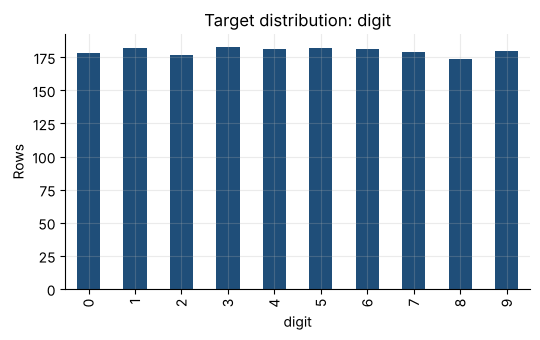

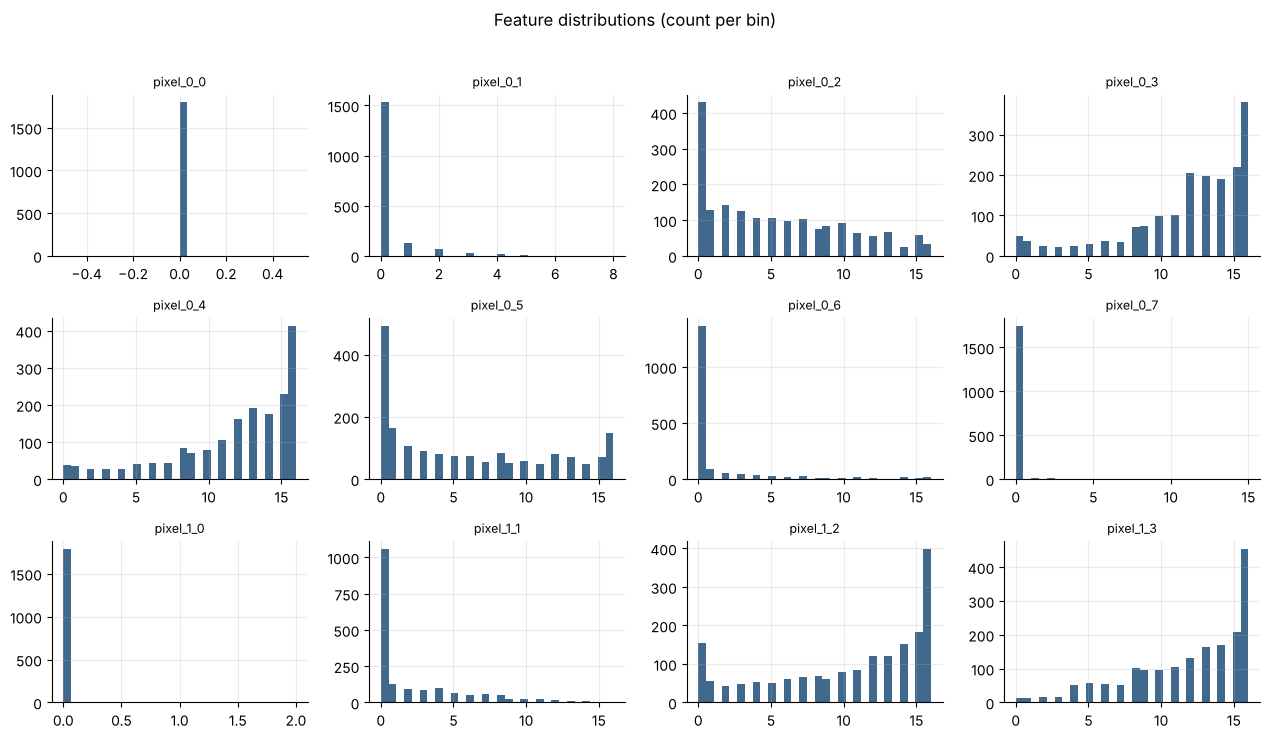

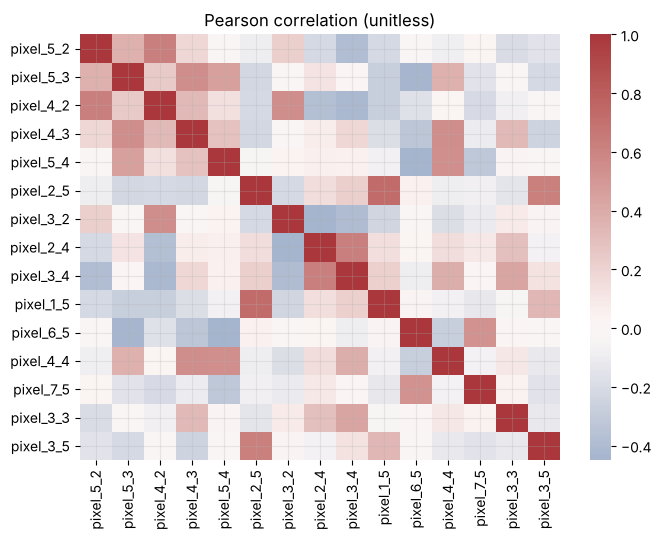

,feature,outliers,percent
0,pixel_0_6,428,23.82
1,pixel_6_1,421,23.43
2,pixel_7_6,267,14.86
3,pixel_0_1,266,14.80
4,pixel_1_6,237,13.19
5,pixel_7_1,219,12.19
6,pixel_5_1,181,10.07
7,pixel_1_1,156,8.68


In [4]:
fig = viz.plot_target(data[TARGET], TASK)
plt.show()
fig = viz.plot_distributions(data.drop(columns=[TARGET]))
plt.show()
fig = viz.plot_correlation(data)
plt.show()
display(viz.outlier_table(data.drop(columns=[TARGET])).head(8))

## 7. Data Preprocessing

Rules used here:

- Split first, then fit imputers, scalers and encoders on the training rows only. This prevents data leakage.
- The test set is touched once, at the end.
- Order inside the pipeline: impute, scale or encode, then model.


In [5]:

X, y = data.drop(columns=[TARGET]), data[TARGET]
X_train, X_val, X_test, y_train, y_val, y_test = split_three_way(X, y, task=TASK, seed=SEED)
print("train / validation / test rows:", len(X_train), len(X_val), len(X_test))
if TASK == "classification":
    split_rates = pd.DataFrame({"train": y_train.value_counts(normalize=True),
                                "validation": y_val.value_counts(normalize=True),
                                "test": y_test.value_counts(normalize=True)}).round(3)
    display(split_rates)
prep = build_preprocessor(X_train, scale=True, encode="onehot")
Xtr = prep.fit_transform(X_train)   # fit on train only
Xva, Xte = prep.transform(X_val), prep.transform(X_test)
print("transformed train shape:", Xtr.shape)

train / validation / test rows: 1077 360 360


,train,validation,test
digit,,,
0,0.098,0.100,0.100
1,0.101,0.103,0.100
2,0.099,0.097,0.097
3,0.101,0.103,0.103
4,0.101,0.100,0.100
5,0.101,0.100,0.103
6,0.101,0.100,0.100
7,0.099,0.100,0.100
8,0.097,0.097,0.097


transformed train shape: (1077, 64)


## 8. Algorithm Implementation

### 8.1 Concept

Only points near the boundary shape it. The kernel measures similarity, so the boundary can curve around digit classes.

### 8.2 Python implementation from scratch

We implement a linear SVM by sub-gradient descent on the hinge loss for the binary task 'is this an 8?' and compare with `LinearSVC`.

In [6]:
from sklearn.svm import LinearSVC
ytr8 = np.where(y_train.values == 8, 1.0, -1.0)
yva8 = np.where(y_val.values == 8, 1.0, -1.0)
w, b, lam, lr = np.zeros(Xtr.shape[1]), 0.0, 0.01, 0.05
for epoch in range(300):
    margin = ytr8 * (Xtr @ w + b)
    active = margin < 1                                  # points inside margin
    grad_w = lam * w - (ytr8[active, None] * Xtr[active]).sum(axis=0) / len(Xtr)
    grad_b = -ytr8[active].sum() / len(Xtr)
    w -= lr * grad_w
    b -= lr * grad_b
pred = np.sign(Xva @ w + b)
ref = LinearSVC(C=1.0, max_iter=20000).fit(Xtr, ytr8)
print("validation accuracy for 'is it an 8', scratch:", round(float(np.mean(pred == yva8)), 4), "| LinearSVC:", round(float(ref.score(Xva, yva8)), 4))
print("share of training points inside the margin:", round(float(active.mean()), 3))

validation accuracy for 'is it an 8', scratch: 0.9556 | LinearSVC: 0.9417
share of training points inside the margin: 0.168


### 8.3 Library implementation

The estimator is wrapped in a pipeline so imputation, scaling and encoding are fitted on training rows only.

### 8.4 Important parameters

| Parameter | Meaning |
|---|---|
| `C` | Cost of margin violations. Large C fits training data harder. |
| `gamma` | RBF reach. Large gamma means very local boundaries. |
| `kernel` | `rbf`, `linear`, `poly`. |
| `probability` | Fit Platt scaling for probabilities (slower). |

## 9. Model Training

Procedure: fit on the training rows, choose one hyperparameter on the validation rows, refit on training plus validation, then evaluate once on the test rows. The random seed is fixed (`SEED = 42`). 

In [7]:
SELECT = "F1"
LOWER_IS_BETTER = False
SCORING = "f1_macro"
SWEEP_PARAM = "model__C"
SWEEP_VALUES = [0.1, 1, 10, 100]

def build_pipeline():
    return make_model_pipeline(X_train, SVC(kernel="rbf", gamma="scale", probability=True, random_state=SEED), scale=True, encode="onehot")

pipe = build_pipeline()
print(pipe.named_steps["model"])
rows = []
for value in SWEEP_VALUES:
    candidate = clone(pipe).set_params(**{SWEEP_PARAM: value}).fit(X_train, y_train)
    rows.append({SWEEP_PARAM: value, **evaluate_estimator(candidate, X_val, y_val, TASK)})
sweep = pd.DataFrame(rows).set_index(SWEEP_PARAM)
display(sweep[[c for c in [SELECT, "R2", "MAE", "Accuracy", "F1", "ROC_AUC", "PR_AUC"] if c in sweep.columns]].round(4))
best_value = sweep[SELECT].idxmin() if LOWER_IS_BETTER else sweep[SELECT].idxmax()
print("best", SWEEP_PARAM, "on validation:", best_value)
final_model = clone(pipe).set_params(**{SWEEP_PARAM: best_value})
X_trainval, y_trainval = pd.concat([X_train, X_val]), pd.concat([y_train, y_val])
final_model.fit(X_trainval, y_trainval)   # refit before test
print("refit on train plus validation rows")

SVC(probability=True, random_state=42)


,F1,Accuracy,F1
model__C,,,
0.1,0.9144,0.9139,0.9144
1.0,0.9888,0.9889,0.9888
10.0,0.9916,0.9917,0.9916
100.0,0.9916,0.9917,0.9916


best model__C on validation: 10.0


refit on train plus validation rows


## 10. Evaluation

Classification metrics: accuracy, precision, recall, F1, ROC-AUC and PR-AUC, plus the confusion matrix. With imbalanced classes accuracy alone misleads, so the model is chosen on F1 or PR-AUC as stated in the training cell.

A dummy model gives the floor every real model must beat.

In [8]:
baseline = DummyRegressor(strategy="mean") if TASK == "regression" else DummyClassifier(strategy="prior")
baseline = make_model_pipeline(X_train, baseline, scale=False).fit(X_trainval, y_trainval)
test_metrics = evaluate_estimator(final_model, X_test, y_test, TASK)
baseline_metrics = evaluate_estimator(baseline, X_test, y_test, TASK)
print("Test set, scored once after model choice")
display(compare_models({"baseline": baseline_metrics, "SVC": test_metrics}))
cv = cross_validate(final_model, X_trainval, y_trainval, cv=5, scoring=SCORING, n_jobs=1)
cv_scores = cv["test_score"]
print(f"5-fold CV {SCORING}: mean {cv_scores.mean():.4f}, std {cv_scores.std(ddof=1):.4f}")
record = ExperimentRecord(notebook=NOTEBOOK_ID, family="supervised", algorithm="SVC", dataset="digits",
                          task=TASK, seed=SEED, config={"param": SWEEP_PARAM, "value": str(best_value)},
                          metrics={k: float(v) for k, v in test_metrics.items()},
                          extra={"baseline": {k: float(v) for k, v in baseline_metrics.items()},
                                 "cv_mean": float(cv_scores.mean()), "cv_std": float(cv_scores.std(ddof=1)),
                                 "cv_scoring": SCORING, "select_metric": SELECT})
print("saved", record.save().name)

Test set, scored once after model choice


,Accuracy,Precision,Recall,F1,ROC_AUC_ovr
baseline,0.1000,0.0100,0.1000,0.0182,0.5000
SVC,0.9806,0.9811,0.9804,0.9805,0.9995


5-fold CV f1_macro: mean 0.9819, std 0.0079
saved support_vector_machine.json


## 11. Visualization

All plots use the test rows unless the title says otherwise.

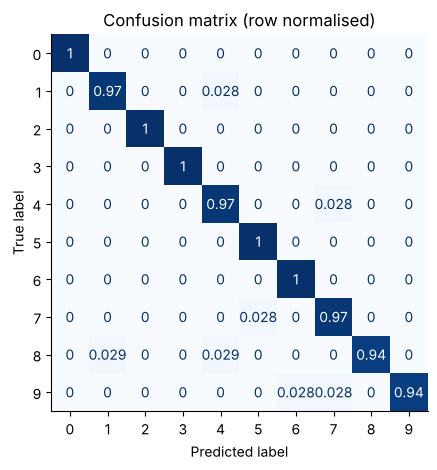

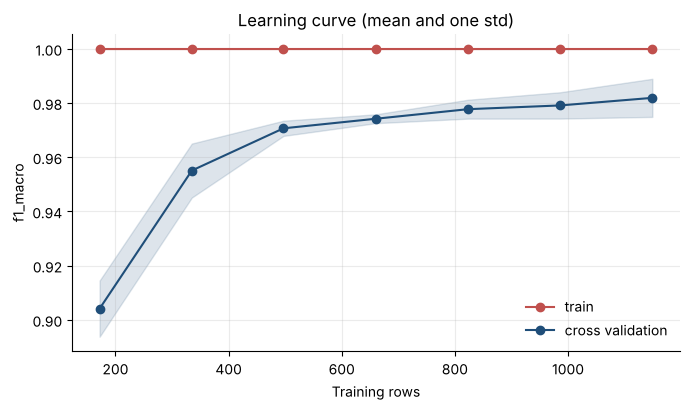

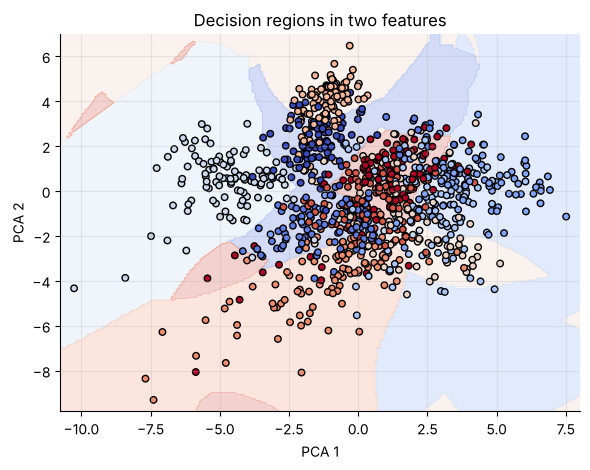

In [9]:
pred = final_model.predict(X_test)
labels = bundle.target_names or None
fig = viz.plot_confusion(y_test, pred, labels=labels)
save_figure(fig, NOTEBOOK_ID, "confusion"); plt.show()
if y_test.nunique() == 2:
    fig = viz.plot_roc_pr(final_model, X_test, y_test)
    save_figure(fig, NOTEBOOK_ID, "roc_pr"); plt.show()
fig = viz.plot_learning_curve(final_model, X_trainval, y_trainval, scoring=SCORING)
save_figure(fig, NOTEBOOK_ID, "learning_curve"); plt.show()
# decision regions in two PCA axes
pca_view = PCA(n_components=2, random_state=SEED).fit(Xtr)
model_for_plot = clone(final_model.named_steps["model"])
fig = viz.plot_decision_boundary(lambda: clone(model_for_plot), pca_view.transform(Xtr), y_train.values,
                                 names=["PCA 1", "PCA 2"])
save_figure(fig, NOTEBOOK_ID, "decision_regions"); plt.show()

## 12. Interpretation

Permutation importance shows which inputs the model relies on. The confusion matrix shows which classes are mixed up, and the list of misclassified rows is the starting point for error analysis. A model is only as good as the cases it fails on.

In [10]:
print("Permutation importance is skipped: the features are raw pixels, so single pixel importance is not meaningful.")
errors = (y_test.values - final_model.predict(X_test)) if TASK == "regression" else (y_test.values != final_model.predict(X_test))
if TASK == "regression":
    worst = pd.DataFrame({"actual": y_test.values, "predicted": final_model.predict(X_test)}, index=y_test.index)
    worst["abs_error"] = (worst["actual"] - worst["predicted"]).abs()
    print("Largest test errors:")
    display(worst.sort_values("abs_error", ascending=False).head(5).round(3))
else:
    print("Misclassified test rows:", int(errors.sum()), "of", len(errors))
print()
print(f"Test {SELECT}: {test_metrics[SELECT]:.4f} | baseline {SELECT}: {baseline_metrics[SELECT]:.4f}")
print(f"Cross validation spread (std): {cv_scores.std(ddof=1):.4f}. A test gap larger than this spread is meaningful.")

Permutation importance is skipped: the features are raw pixels, so single pixel importance is not meaningful.
Misclassified test rows: 7 of 360

Test F1: 0.9805 | baseline F1: 0.0182
Cross validation spread (std): 0.0079. A test gap larger than this spread is meaningful.


## 13. Experiments and Challenges

### Experiment 1: C and gamma grid

Cross validated macro F1 over a small grid (no probability fitting, to save time).

In [11]:
from sklearn.model_selection import cross_val_score
rows = []
for C in [0.1, 1, 10]:
    for gamma in [0.0005, 0.002, 0.008, 0.03]:
        s = cross_val_score(make_model_pipeline(X_trainval, SVC(C=C, gamma=gamma)), X_trainval, y_trainval, cv=3, scoring="f1_macro")
        rows.append({"C": C, "gamma": gamma, "cv_f1": s.mean()})
display(pd.DataFrame(rows).pivot(index="C", columns="gamma", values="cv_f1").round(3))

gamma,0.0005,0.0020,0.0080,0.0300
C,,,,
0.1,0.078,0.657,0.912,0.911
1.0,0.913,0.954,0.976,0.972
10.0,0.973,0.979,0.980,0.974


### Experiment 2: Kernels

Compare linear, polynomial and RBF kernels.

In [12]:
from sklearn.model_selection import cross_val_score
for kernel in ["linear", "poly", "rbf"]:
    s = cross_val_score(make_model_pipeline(X_trainval, SVC(kernel=kernel)), X_trainval, y_trainval, cv=5, scoring="f1_macro")
    print(f"{kernel}: CV macro F1 {s.mean():.3f} +- {s.std(ddof=1):.3f}")

linear: CV macro F1 0.981 +- 0.007


poly: CV macro F1 0.951 +- 0.017


rbf: CV macro F1 0.981 +- 0.005


### Experiment 3: Support vectors versus C

A larger C means fewer margin violations and usually fewer support vectors.

In [13]:
for C in [0.1, 1, 10, 100]:
    m = SVC(C=C, gamma="scale").fit(Xtr, y_train)
    print(f"C={C}: support vectors {m.n_support_.sum()} of {len(Xtr)}, validation accuracy {m.score(Xva, y_val):.3f}")

C=0.1: support vectors 944 of 1077, validation accuracy 0.914
C=1: support vectors 612 of 1077, validation accuracy 0.989
C=10: support vectors 602 of 1077, validation accuracy 0.992
C=100: support vectors 602 of 1077, validation accuracy 0.992


### Exercises for learners

1. Repeat the notebook with `SEED = 7` and report how much the headline metric changes.
2. Change the metric used for model choice and see whether the chosen value changes.
3. Replace the validation sweep with `GridSearchCV` and compare the chosen value.

## 14. Research Discussion

Cortes and Vapnik reported strong digit recognition with polynomial support vector networks. Our digits are a different, smaller dataset, so we can only note that kernel SVMs again perform strongly on digit images.

**Dataset and method differences.** The papers above use other datasets, other splits and often other implementations. We do not claim that our numbers agree or disagree with them. What this notebook can show is whether the behaviour described in the paper (for example the effect of a parameter) appears on our data.

**Possible improvements.** Use data augmentation, larger images (MNIST), and nested cross validation for C and gamma.

**Research limitations.** One dataset, one split seed for the headline number, and small test sets for the UCI data. Cross validation spread is reported to show how unstable a single split can be.

## 15. Summary and Further Reading

**Key takeaways**

- Margin maximisation gives good generalisation.
- Scale features and tune C and gamma.
- Support vectors are the only points that matter.

**Use cases.** Small image sets, text classification, bioinformatics.

**Limitations.** Poor scaling to very large data.

**Recommended next notebook.** Naive Bayes.

**Further reading.** See `references.md` in this folder and the library documentation for the classes used above.